# Screening COCONUT Natural Products with Your Trained AChE Model

Applies the Random Forest models you trained on ChEMBL AChE data to the
**COCONUT** (COlleCtion of Open Natural prodUcTs) database, to flag natural
products that look like they could be AChE inhibitors.

**Before running:** upload `rf_classifier.pkl`, `rf_regressor.pkl`, and
`ache_data_featurized_clean.csv` from your previous run (they were in the
`qsar_ache_results.zip` you downloaded) to this Colab session -- or place
them on your Drive and update the paths in cell 2 below.

**Important framing:** this is a rough virtual pre-screen, not a discovery
tool. Two things make it meaningfully more trustworthy than a bare
prediction list: (1) an **applicability domain** check -- since natural
products are structurally quite different from the mostly-synthetic ChEMBL
molecules the model was trained on, predictions are only as trustworthy as
the query molecule is *similar* to something the model has actually seen;
and (2) a **known-compound sanity check** -- galantamine and huperzine A are
real, well-studied natural-product AChE inhibitors (one is an approved
Alzheimer's drug), so if the model scores them sensibly, that's a genuine
external validation, not just a self-consistency check.

## 1. Setup

In [1]:
!pip install rdkit -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.4/37.4 MB 44.6 MB/s eta 0:00:00


In [2]:
import warnings, os, time, json, pickle, zipfile, glob
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from rdkit import Chem
from rdkit.Chem import AllChem
from rdkit import DataStructs
from rdkit import RDLogger
RDLogger.DisableLog("rdApp.*")

sns.set_style("whitegrid")
np.random.seed(42)

OUT = "coconut_screen_outputs"
os.makedirs(OUT, exist_ok=True)

N_BITS = 1024          # MUST match what the trained model was built on
SAMPLE_N = None        # set to None to screen the FULL COCONUT library (~700k-1M
                        # compounds; expect this to take significantly longer --
                        # see the time estimate printed after featurization).
                        # Start with a sample to confirm everything works first.
AD_SIMILARITY_FLOOR = 0.30   # a common rule-of-thumb minimum Tanimoto similarity
                              # to the training set before a prediction is
                              # considered "in domain" enough to trust at all.

T0 = time.time()
def tprint(msg):
    print(f"[{time.time()-T0:7.1f}s] {msg}", flush=True)

## 2. Load your trained model + training data

In [7]:
from pathlib import Path
import pickle
import pandas as pd

# Directory containing all model/data files
BASE_DIR = Path("/content/drive/MyDrive/research/Acetylcholinesterase/qsar_outputs")

# File paths
clf_path = BASE_DIR / "rf_classifier.pkl"
reg_path = BASE_DIR / "rf_regressor.pkl"
train_path = BASE_DIR / "ache_data_featurized_clean.csv"

# Check that files exist
assert clf_path.exists(), f"Classifier not found: {clf_path}"
assert reg_path.exists(), f"Regressor not found: {reg_path}"
assert train_path.exists(), f"Training data not found: {train_path}"

# Load classifier
with open(clf_path, "rb") as f:
    rf_clf = pickle.load(f)

# Load regressor
with open(reg_path, "rb") as f:
    rf_reg = pickle.load(f)

# Load training dataset
train_df = pd.read_csv(train_path)

print(f"Loaded classifier, regressor, and {len(train_df)} training compounds")

# Check number of features
assert rf_clf.n_features_in_ == N_BITS, \
    f"Classifier expects {rf_clf.n_features_in_} features but N_BITS={N_BITS} -- fix N_BITS above."

Loaded classifier, regressor, and 6268 training compounds


In [5]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 3. Download COCONUT (natural products, CSV format)

Downloads the "lite" CSV release directly from COCONUT's official host.
**If this link 404s** (COCONUT re-releases monthly, so the exact filename
changes), go to https://coconut.naturalproducts.net/download , right-click
the "Natural Products - CSV format" (smaller/lite) link, copy the URL, and
paste it in place of `COCONUT_URL` below.

In [8]:
COCONUT_URL = "https://coconut.s3.uni-jena.de/prod/downloads/2026-08/coconut_csv-08-2026.zip"

!wget -q -c "{COCONUT_URL}" -O coconut_data.zip
tprint(f"Downloaded {os.path.getsize('coconut_data.zip') / 1e6:.1f} MB")

with zipfile.ZipFile("coconut_data.zip") as z:
    z.extractall("coconut_data")
    names = z.namelist()

csv_files = glob.glob("coconut_data/**/*.csv", recursive=True)
assert csv_files, f"No CSV found inside the zip. Contents were: {names[:20]}"
coconut_csv_path = max(csv_files, key=os.path.getsize)  # pick the largest if multiple
tprint(f"Found CSV: {coconut_csv_path}")

[  354.0s] Downloaded 248.0 MB
[  361.4s] Found CSV: coconut_data/coconut_csv-08-2026.csv


## 4. Load COCONUT and auto-detect the SMILES / ID columns

In [9]:
ext_df = pd.read_csv(coconut_csv_path, low_memory=False)
tprint(f"Loaded {len(ext_df)} compounds from COCONUT")
print("Columns found:", ext_df.columns.tolist())

def find_col(df, keywords, exclude=()):
    for c in df.columns:
        cl = c.lower()
        if any(k in cl for k in keywords) and not any(e in cl for e in exclude):
            return c
    return None

smiles_col = find_col(ext_df, ["smiles"])
id_col = find_col(ext_df, ["identifier", "coconut_id"], exclude=["smiles"]) or find_col(ext_df, ["id"], exclude=["smiles"])
name_col = find_col(ext_df, ["name"], exclude=["smiles", "filename"])

assert smiles_col is not None, (
    f"Could not auto-detect a SMILES column among {ext_df.columns.tolist()}. "
    f"Set smiles_col = '<the right column name>' manually and re-run from here."
)
print(f"\nDetected -> SMILES column: '{smiles_col}'  |  ID column: '{id_col}'  |  name column: '{name_col}'")

# Quick validation: confirm a sample of this column actually parses as SMILES
sample_valid = ext_df[smiles_col].dropna().head(20).apply(lambda s: Chem.MolFromSmiles(str(s)) is not None)
assert sample_valid.mean() > 0.5, "Detected SMILES column doesn't look like valid SMILES -- check column names above."
print(f"Sample validity check: {sample_valid.mean()*100:.0f}% of a 20-row sample parsed correctly.")

if SAMPLE_N is not None and len(ext_df) > SAMPLE_N:
    ext_df = ext_df.sample(SAMPLE_N, random_state=42).reset_index(drop=True)
    tprint(f"Subsampled to {SAMPLE_N} compounds (set SAMPLE_N = None in cell above for the full library)")

[  383.8s] Loaded 738827 compounds from COCONUT
Columns found: ['identifier', 'canonical_smiles', 'standard_inchi', 'standard_inchi_key', 'name', 'iupac_name', 'annotation_level', 'total_atom_count', 'heavy_atom_count', 'molecular_weight', 'exact_molecular_weight', 'molecular_formula', 'alogp', 'topological_polar_surface_area', 'rotatable_bond_count', 'hydrogen_bond_acceptors', 'hydrogen_bond_donors', 'hydrogen_bond_acceptors_lipinski', 'hydrogen_bond_donors_lipinski', 'lipinski_rule_of_five_violations', 'aromatic_rings_count', 'qed_drug_likeliness', 'formal_charge', 'fractioncsp3', 'number_of_minimal_rings', 'van_der_walls_volume', 'contains_sugar', 'contains_ring_sugars', 'contains_linear_sugars', 'murcko_framework', 'np_likeness', 'chemical_class', 'chemical_sub_class', 'chemical_super_class', 'direct_parent_classification', 'np_classifier_pathway', 'np_classifier_superclass', 'np_classifier_class', 'np_classifier_is_glycoside', 'organisms', 'collections', 'dois', 'synonyms', 'cas']

## 5. Featurize (Morgan/ECFP4 fingerprints, same settings as training)

In [ ]:
def featurize(smi):
    mol = Chem.MolFromSmiles(smi)
    if mol is None:
        return None, None
    bv = AllChem.GetMorganFingerprintAsBitVect(mol, 2, nBits=N_BITS)
    arr = np.zeros((N_BITS,), dtype=np.int8)
    DataStructs.ConvertToNumpyArray(bv, arr)
    return arr, bv

t_start = time.time()
arrs, bvs, valid_idx = [], [], []
for i, smi in enumerate(ext_df[smiles_col]):
    arr, bv = featurize(str(smi))
    if arr is not None:
        arrs.append(arr); bvs.append(bv); valid_idx.append(i)
    if i > 0 and i % 100000 == 0:
        tprint(f"  featurized {i}/{len(ext_df)}...")

rate = len(arrs) / max(time.time() - t_start, 1e-6)
X_ext = np.array(arrs)
ext_valid = ext_df.iloc[valid_idx].reset_index(drop=True)
tprint(f"Featurized {len(ext_valid)}/{len(ext_df)} compounds ({rate:.0f} mol/s)")
if SAMPLE_N is None:
    print(f"(Full-library run -- at this rate, the applicability-domain step in section 7 "
          f"will take roughly {len(ext_valid) * len(train_df) / 2e6 / 60:.1f} extra minutes.)")

[  432.0s]   featurized 100000/738827...
[  479.1s]   featurized 200000/738827...
[  526.7s]   featurized 300000/738827...
[  573.9s]   featurized 400000/738827...
[  621.3s]   featurized 500000/738827...
[  669.5s]   featurized 600000/738827...
[  717.1s]   featurized 700000/738827...
[  738.7s] Featurized 738823/738827 compounds (2093 mol/s)
(Full-library run -- at this rate, the applicability-domain step in section 7 will take roughly 38.6 extra minutes.)


## 6. Predict: P(active) and pIC50 for every natural product

In [ ]:
proba = rf_clf.predict_proba(X_ext)[:, 1]
pred_pIC50 = rf_reg.predict(X_ext)
ext_valid["pred_P_active"] = proba
ext_valid["pred_pIC50"] = pred_pIC50
tprint("Predictions complete")

print(f"\nPredicted active (P>0.5): {(proba > 0.5).sum()} / {len(ext_valid)} "
      f"({(proba > 0.5).mean()*100:.1f}%)")

[  820.2s] Predictions complete

Predicted active (P>0.5): 188855 / 738823 (25.6%)


## 7. Applicability domain -- how much should we trust each prediction?

For every natural product, find its maximum Tanimoto similarity to any
compound in the AChE training set. Low similarity = the model is
extrapolating into chemistry it has never seen, and the prediction should
be trusted much less regardless of how confident it looks.

In [ ]:
train_bvs = []
for smi in train_df["canonical_smiles"]:
    mol = Chem.MolFromSmiles(smi)
    if mol is not None:
        train_bvs.append(AllChem.GetMorganFingerprintAsBitVect(mol, 2, nBits=N_BITS))
tprint(f"Prepared {len(train_bvs)} training fingerprints")

t_start = time.time()
max_sims = []
for i, bv in enumerate(bvs):
    max_sims.append(max(DataStructs.BulkTanimotoSimilarity(bv, train_bvs)))
    if i > 0 and i % 20000 == 0:
        elapsed = time.time() - t_start
        remaining = elapsed / i * (len(bvs) - i)
        tprint(f"  AD check {i}/{len(bvs)}... (~{remaining/60:.1f} min remaining)")

ext_valid["AD_max_similarity"] = max_sims
ext_valid["in_domain"] = ext_valid["AD_max_similarity"] >= AD_SIMILARITY_FLOOR
tprint(f"Applicability domain check done. {ext_valid['in_domain'].mean()*100:.1f}% of "
       f"compounds are above the {AD_SIMILARITY_FLOOR} similarity floor.")

[  822.2s] Prepared 6268 training fingerprints
[  850.8s]   AD check 20000/738823... (~17.1 min remaining)
[  879.8s]   AD check 40000/738823... (~16.8 min remaining)
[  906.8s]   AD check 60000/738823... (~15.9 min remaining)
[  935.1s]   AD check 80000/738823... (~15.5 min remaining)
[  964.6s]   AD check 100000/738823... (~15.2 min remaining)
[  993.8s]   AD check 120000/738823... (~14.7 min remaining)
[ 1022.6s]   AD check 140000/738823... (~14.3 min remaining)
[ 1051.4s]   AD check 160000/738823... (~13.8 min remaining)
[ 1080.9s]   AD check 180000/738823... (~13.4 min remaining)
[ 1110.0s]   AD check 200000/738823... (~12.9 min remaining)
[ 1137.7s]   AD check 220000/738823... (~12.4 min remaining)
[ 1166.8s]   AD check 240000/738823... (~11.9 min remaining)
[ 1196.4s]   AD check 260000/738823... (~11.5 min remaining)
[ 1226.7s]   AD check 280000/738823... (~11.0 min remaining)
[ 1257.8s]   AD check 300000/738823... (~10.6 min remaining)
[ 1288.6s]   AD check 320000/738823... (~1

## 8. Known-compound sanity check

Score galantamine and huperzine A directly -- real, literature-confirmed
natural-product AChE inhibitors the model never saw during training. This
is a genuine external validation, independent of whether COCONUT itself
contains them.

In [ ]:
known_refs = {
    "galantamine (approved Alzheimer's drug, moderate AChE inhibitor, literature IC50 ~0.3-0.8 uM)":
        "COc1ccc2c3c1O[C@H]1C[C@@H](O)C=C[C@@]31CCN(C)C2",
    "huperzine A (potent natural AChE inhibitor, literature IC50 ~0.08-0.5 uM)":
        "C/C=C1\\[C@H]2C=C(C)C[C@]1(N)c1ccc(=O)[nH]c1C2",
}

print("Direct model scoring of known natural AChE inhibitors:\n")
for label, smi in known_refs.items():
    arr, bv = featurize(smi)
    p = rf_clf.predict_proba(arr.reshape(1, -1))[0, 1]
    pic50 = rf_reg.predict(arr.reshape(1, -1))[0]
    ad = max(DataStructs.BulkTanimotoSimilarity(bv, train_bvs))
    print(f"{label}\n  -> predicted P(active)={p:.3f}  predicted pIC50={pic50:.2f}  AD similarity={ad:.2f}\n")

# Also check whether COCONUT's own name column (if present) contains either compound
if name_col is not None:
    hits = ext_valid[ext_valid[name_col].astype(str).str.contains(
        "galantamine|galanthamine|huperzine", case=False, na=False)]
    if len(hits):
        print("Found in the COCONUT library itself:")
        print(hits[[id_col, name_col, "pred_P_active", "pred_pIC50", "AD_max_similarity"]].to_string(index=False))
    else:
        print("Not found by name in this COCONUT sample/name column (may be named differently, or excluded by SAMPLE_N subsampling).")

Direct model scoring of known natural AChE inhibitors:

galantamine (approved Alzheimer's drug, moderate AChE inhibitor, literature IC50 ~0.3-0.8 uM)
  -> predicted P(active)=0.570  predicted pIC50=5.74  AD similarity=1.00

huperzine A (potent natural AChE inhibitor, literature IC50 ~0.08-0.5 uM)
  -> predicted P(active)=0.875  predicted pIC50=6.82  AD similarity=1.00

Found in the COCONUT library itself:
  identifier                              name  pred_P_active  pred_pIC50  AD_max_similarity
CNP0510085.1              6-Hydroxyhuperzine A       0.486667    5.771038           0.596154
CNP0244416.1          N-Desmethyl Galanthamine       0.447707    5.375098           1.000000
CNP0267772.1                       huperzine b       0.790540    6.114654           1.000000
CNP0356706.2                       Huperzine A       0.874781    6.823560           1.000000
CNP0356706.4                       Huperzine A       0.874781    6.823560           1.000000
CNP0244416.2                Epino

## 9. Rank candidates

In [ ]:
# Only rank compounds inside the applicability domain -- out-of-domain "hits"
# are much more likely to be noise than real signal.
candidates = ext_valid[ext_valid["in_domain"]].copy()
candidates = candidates.sort_values(["pred_P_active", "pred_pIC50"], ascending=False)

top_n = 50
top_candidates = candidates.head(top_n)
display_cols = [c for c in [id_col, name_col, smiles_col, "pred_P_active", "pred_pIC50", "AD_max_similarity"] if c is not None]

print(f"Top {top_n} candidates (in applicability domain, ranked by predicted P(active)):")
top_candidates[display_cols].to_csv(f"{OUT}/top_candidates.csv", index=False)
top_candidates[display_cols].head(20)

Top 50 candidates (in applicability domain, ranked by predicted P(active)):


,identifier,name,canonical_smiles,pred_P_active,pred_pIC50,AD_max_similarity
527435,CNP0592161.0,TACRINE(8)-4-AMINOQUINOLINE,C1=CC=C2C(NCCCCCCCCNC3=C4CCCCC4=NC4=CC=CC=C34)...,1.000000,7.826756,1.000000
40116,CNP0170523.2,(S)-donepezil,COC1=CC2=C(C=C1OC)C(=O)[C@@H](CC1CCN(CC3=CC=CC...,1.000000,7.521753,1.000000
376633,CNP0170523.1,(R)-donepezil,COC1=CC2=C(C=C1OC)C(=O)[C@H](CC1CCN(CC3=CC=CC=...,1.000000,7.521753,1.000000
112099,CNP0487592.1,Physovenine,CNC(=O)OC1=CC=C2C(=C1)[C@]1(C)CCO[C@@H]1N2C,1.000000,7.483505,1.000000
320229,CNP0556610.1,GANSTIGMINE,CCC1=CC=CC=C1NC(=O)OC1=CC=C2C(=C1)[C@]1(C)CCN(...,1.000000,7.300547,1.000000
377802,CNP0318280.1,DTXSID701108513,CNC(=O)OC1=CC=C2C(=C1)[C@@]1(C)CCN(C)O[C@H]1N2C,1.000000,6.984578,1.000000
442059,CNP0318280.2,Geneserine,CNC(=O)OC1=CC=C2C(=C1)[C@]1(C)CCN(C)O[C@@H]1N2C,1.000000,6.984578,1.000000
174645,CNP0493665.1,Phenserine,CN1CC[C@@]2(C)C3=CC(OC(=O)NC4=CC=CC=C4)=CC=C3N...,1.000000,6.953424,1.000000
140934,CNP0553198.0,Zanapezil,O=C(CCC1CCN(CC2=CC=CC=C2)CC1)C1=CC=C2CCCCNC2=C1,1.000000,6.850433,1.000000
411807,CNP0576170.1,"[(3aS,8bS)-3,8b-dimethyl-1,2,3a,4-tetrahydropy...",CNC(=O)OC1=CC=C2N[C@H]3N(C)CC[C@@]3(C)C2=C1,1.000000,6.811825,1.000000


## 10. Plots

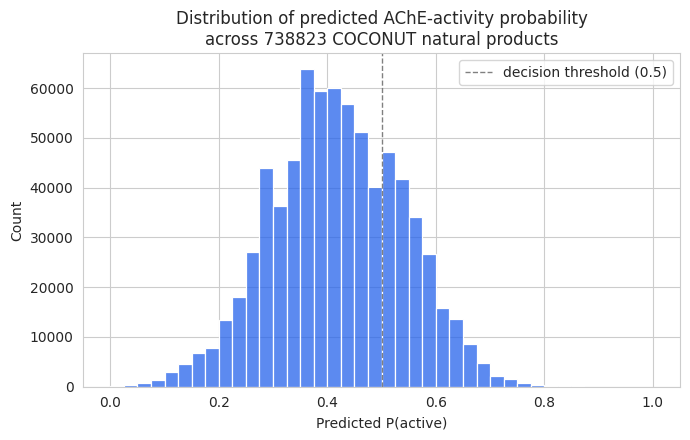

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.histplot(ext_valid["pred_P_active"], bins=40, color="#2563eb", ax=ax)
ax.axvline(0.5, color="gray", linestyle="--", linewidth=1, label="decision threshold (0.5)")
ax.set_xlabel("Predicted P(active)")
ax.set_title(f"Distribution of predicted AChE-activity probability\nacross {len(ext_valid)} COCONUT natural products")
ax.legend()
plt.tight_layout()
plt.savefig(f"{OUT}/fig1_probability_distribution.png", dpi=150)
plt.show()

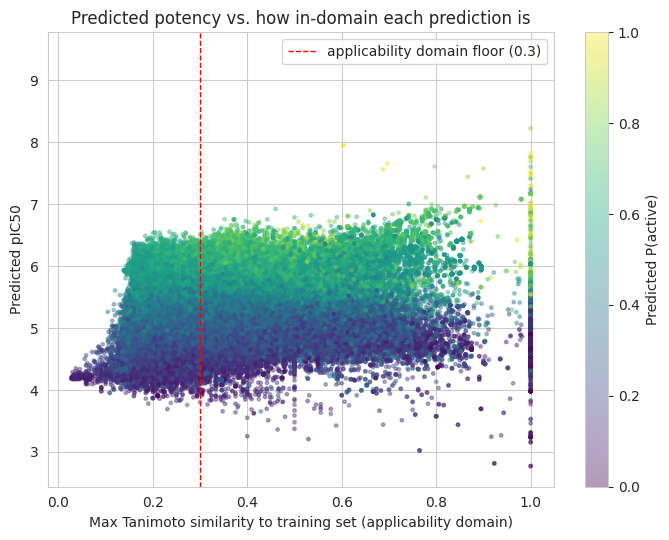


Note: points to the LEFT of the red line are outside the applicability domain --
their predictions are extrapolation and should be trusted much less, however confident they look.


In [ ]:
fig, ax = plt.subplots(figsize=(7, 5.5))
sc = ax.scatter(ext_valid["AD_max_similarity"], ext_valid["pred_pIC50"],
                 c=ext_valid["pred_P_active"], cmap="viridis", s=6, alpha=0.4)
ax.axvline(AD_SIMILARITY_FLOOR, color="red", linestyle="--", linewidth=1,
           label=f"applicability domain floor ({AD_SIMILARITY_FLOOR})")
plt.colorbar(sc, label="Predicted P(active)")
ax.set_xlabel("Max Tanimoto similarity to training set (applicability domain)")
ax.set_ylabel("Predicted pIC50")
ax.set_title("Predicted potency vs. how in-domain each prediction is")
ax.legend()
plt.tight_layout()
plt.savefig(f"{OUT}/fig2_potency_vs_applicability_domain.png", dpi=150)
plt.show()

print("\nNote: points to the LEFT of the red line are outside the applicability domain --")
print("their predictions are extrapolation and should be trusted much less, however confident they look.")

## 11. Save and download everything

In [ ]:
ext_valid.to_csv(f"{OUT}/all_predictions.csv", index=False)

summary = {
    "n_screened": int(len(ext_valid)),
    "n_predicted_active": int((ext_valid['pred_P_active'] > 0.5).sum()),
    "n_in_applicability_domain": int(ext_valid["in_domain"].sum()),
    "AD_similarity_floor": AD_SIMILARITY_FLOOR,
    "sample_n_used": SAMPLE_N,
}
with open(f"{OUT}/screen_summary.json", "w") as f:
    json.dump(summary, f, indent=2)

print(json.dumps(summary, indent=2))

import shutil
shutil.make_archive("coconut_ache_screen_results", "zip", OUT)
tprint("Zipped all results")

from google.colab import files
files.download("coconut_ache_screen_results.zip")

## 12. What to do with this list -- read before trusting any "hit"

This ranks candidates; it does not confirm them. Before treating anything
here as a real lead:

1. **Respect the applicability domain.** A high P(active) on a compound far
   outside the training chemistry (low AD similarity) is much weaker
   evidence than the same score on an in-domain compound.
2. **Check for known compounds.** Many top hits in a natural-product library
   will turn out to already be known AChE inhibitors (alkaloid families
   related to galantamine/huperzine A are a common source) -- genuinely
   useful for validating the model, but not novel.
3. **Visually inspect the top ~20-50 structures** for red flags: reactive
   groups, PAINS-like substructures, and molecules so large/complex they're
   unlikely to be druggable or even correctly handled by 2D fingerprints.
4. **This is a pre-filter, not a result.** A real next step would be
   docking the top candidates against an AChE crystal structure, or
   literature-checking whether any have been reported against
   cholinesterases before, before this becomes something worth writing up.